# Q-transfer with gaze-select + restrict (gsr) — figures & tables

Figures for the q-transfer update (`agent_reports/claude/q-transfer-update-todos.md`, TODO 1), on
`Qwen2.5-Coder-32B-Instruct`, 250 goal heads, α=2, **kv-off**. Report: `agent_reports/claude/analysis/gaze_select_restrict.md`.

Arm: `results/diff/<model>/diff_trigger/ph-goal_250__a2__piv-eq__cl-ppgazerestrict-anceq__seq/{order_diff,order_matched}`.

Metrics are the same as the kv-transfer figures (`transfer.ipynb`), both from `src/diff/eval.py`:
- **causal-shift** (SOLID) = `causal_trigger_rate`: `judge_causal` on the first computation, D vs native B, `both`
  counts as triggered;
- **readout-shift** (HATCHED) = `readout_shift_rate`: GoalScope readout at the pivot, judged D vs B. It is read off the
  selection pass (query transfer + α boost, before the restriction), so it equals the q-transfer readout.

Aggregates are unweighted means over the 4×4 (datatype × direction) cells, as in `transfer.ipynb`.

Outputs → `notebooks/Figures/transfer/{q_crosslang_gsr, q_barcharts_gsr, q_gsr_diff.tex, q_gsr_matched.tex}`.

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import figstyle as F; F.set_style()

GROUP = 'transfer'
MODEL = 'Qwen2.5-Coder-32B-Instruct'
GSR_ARM = os.path.join(env_utils.DEFAULT_RESULTS_DIR, 'diff', MODEL, 'diff_trigger',
                       'ph-goal_250__a2__piv-eq__cl-ppgazerestrict-anceq__seq')
COLOR = F.MODEL_COLOR[MODEL]

VARIANTS = ['order_diff', 'order_matched']
VAR_LBL  = {'order_diff': 'order-diff', 'order_matched': 'order-matched'}
DTS   = ['int', 'str', 'list[int]', 'list[str]']
LANGS = ['python-python', 'python-cpp', 'cpp-python', 'cpp-cpp']
Q_DT  = {'int': 'int', 'str': 'str', 'list[int]': 'list(int)', 'list[str]': 'list(str)'}
LANG_LBL = {'python-python': 'py$\\to$py', 'python-cpp': 'py$\\to$cpp',
            'cpp-python': 'cpp$\\to$py', 'cpp-cpp': 'cpp$\\to$cpp'}

def load(variant, dt, lang):
    d = json.load(open(os.path.join(GSR_ARM, variant, f'{Q_DT[dt]}__{lang}', 'summary.json')))
    d = d[0] if isinstance(d, list) else d
    return d['causal_trigger_rate'], d['readout_shift_rate'], d['n']

# GRID[variant][dt][lang] = (causal-shift, readout-shift, n)
GRID = {v: {dt: {lg: load(v, dt, lg) for lg in LANGS} for dt in DTS} for v in VARIANTS}

def mean_over(g, axis):
    """axis='lang' -> per direction (mean over datatypes); 'dt' -> per datatype. Returns cats, causal, readout."""
    if axis == 'lang':
        cats = LANGS; cells = lambda c: [g[dt][c] for dt in DTS]
    else:
        cats = DTS;   cells = lambda c: [g[c][lg] for lg in LANGS]
    return (cats, np.array([np.mean([x[0] for x in cells(c)]) for c in cats]),
            np.array([np.mean([x[1] for x in cells(c)]) for c in cats]))

for v in VARIANTS:
    g = GRID[v]
    oc = np.mean([g[dt][lg][0] for dt in DTS for lg in LANGS]); orr = np.mean([g[dt][lg][1] for dt in DTS for lg in LANGS])
    cats, c, r = mean_over(g, 'lang')
    print(f'{VAR_LBL[v]:13s} overall causal={oc:.3f} readout={orr:.3f} | by direction (causal / readout): '
          + '  '.join(f'{lg} {cc:.2f}/{rr:.2f}' for lg, cc, rr in zip(cats, c, r)))
print('n per cell:', sorted({g[dt][lg][2] for g in GRID.values() for dt in DTS for lg in LANGS}))

order-diff    overall causal=0.572 readout=0.412 | by direction (causal / readout): python-python 0.66/0.51  python-cpp 0.55/0.38  cpp-python 0.51/0.36  cpp-cpp 0.56/0.40
order-matched overall causal=0.871 readout=0.668 | by direction (causal / readout): python-python 0.88/0.73  python-cpp 0.84/0.63  cpp-python 0.88/0.68  cpp-cpp 0.88/0.63
n per cell: [32]


In [3]:
# figstyle.metric_kw: causal-shift = SOLID, readout-shift = HATCHED (same as transfer.ipynb)
def grouped_metric_bars(ax, cats, cat_labels, causal, readout, color=COLOR, w=0.38, annotate=False):
    x = np.arange(len(cats))
    ax.bar(x - w/2, causal,  w, **F.metric_kw('causal',  color))
    ax.bar(x + w/2, readout, w, **F.metric_kw('readout', color))
    if annotate:
        for xi, v in [*zip(x - w/2, causal), *zip(x + w/2, readout)]:
            ax.text(xi, v + .015, f'{v:.2f}', ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(cat_labels)
    ax.set_ylim(0, 1.05); ax.set_ylabel('shift rate')

def transfer_legend_handles(color=COLOR):
    # facecolor, not color: on a Patch, color= also sets the edge, so the hatch would be drawn in the fill colour
    return [Patch(label='causal-shift',  facecolor=color, edgecolor='white', linewidth=0.6),
            Patch(label='readout-shift', facecolor=color, edgecolor='white', linewidth=0.6, hatch=F.HATCH)]

## `q_crosslang_gsr` — main-text panel, order-diff only

Causal-shift (solid) and readout-shift (hatched) by language direction, mean over datatypes. Replaces the bar panel
of `q-transfer-main-crop.pdf`; same layout as the old `q_crosslang`.

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_crosslang_gsr.pdf
order-diff ALL causal 0.572 / readout 0.412


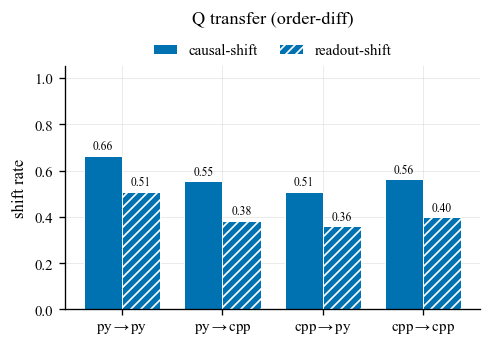

In [4]:
cats, c, r = mean_over(GRID['order_diff'], 'lang')
fig, ax = plt.subplots(figsize=(4.2, 3.0))
grouped_metric_bars(ax, cats, [LANG_LBL[l] for l in cats], c, r, annotate=True)
ax.set_title('Q transfer (order-diff)')
F.legend_top(ax, handles=transfer_legend_handles(), labels=['causal-shift', 'readout-shift'])
fig.tight_layout()
print('saved', F.save_fig(fig, GROUP, 'q_crosslang_gsr'))
print(f'order-diff ALL causal {c.mean():.3f} / readout {r.mean():.3f}')
plt.show()

## `q_barcharts_gsr` — appendix, both orderings

Top row order-matched, bottom row order-diff; left by language direction (mean over datatypes), right by datatype
(mean over directions).

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_barcharts_gsr.pdf


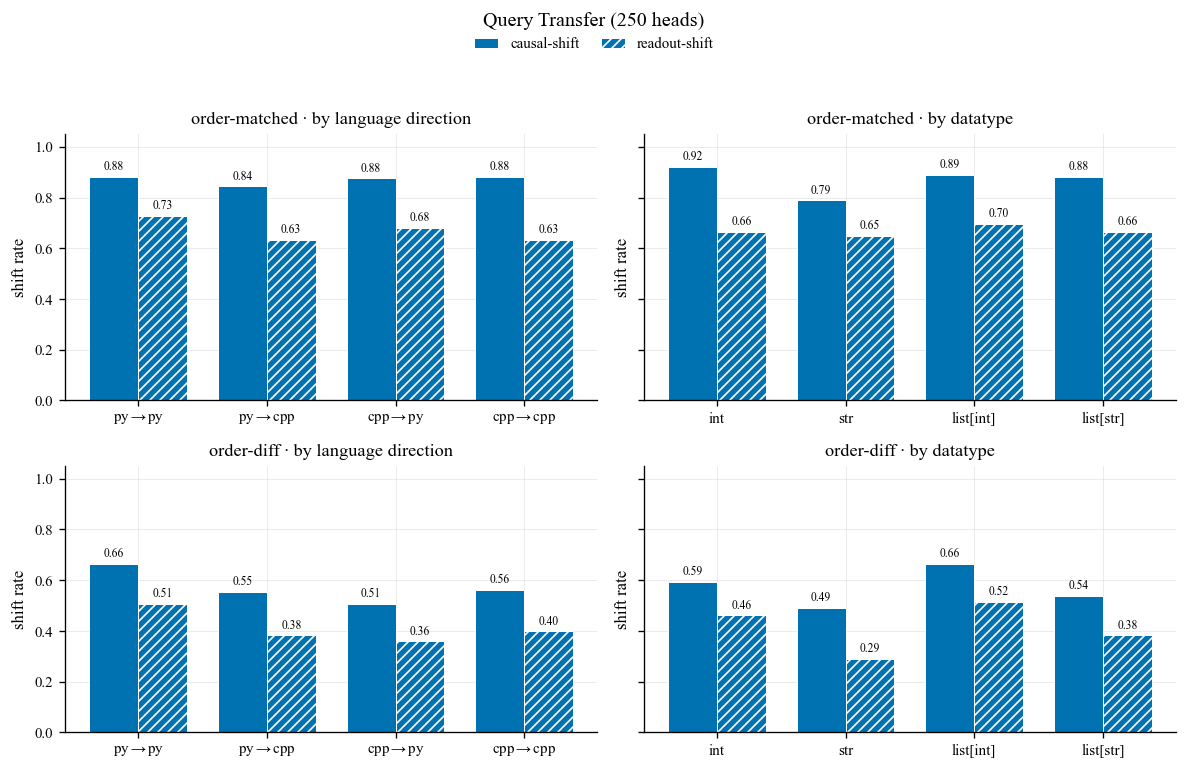

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharey=True)
for i, v in enumerate(['order_matched', 'order_diff']):
    for j, (axis, lbl, sub) in enumerate([('lang', LANG_LBL, 'by language direction'), ('dt', None, 'by datatype')]):
        cats, c, r = mean_over(GRID[v], axis)
        grouped_metric_bars(axes[i][j], cats, [lbl[x] for x in cats] if lbl else cats, c, r, annotate=True)
        axes[i][j].set_title(f'{VAR_LBL[v]} · {sub}')
fig.suptitle('Query Transfer (250 heads)', y=0.995, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.935))
hs = transfer_legend_handles()
fig.legend(handles=hs, labels=[h.get_label() for h in hs], loc='lower center', bbox_to_anchor=(0.5, 0.932),
           ncol=len(hs), frameon=False, handlelength=1.6, columnspacing=1.4, borderaxespad=0.2)
print('saved', F.save_fig(fig, GROUP, 'q_barcharts_gsr')); plt.show()

## Tables — 4×4 grids (`causal-shift / readout-shift`), same format as `tab:q-matched` / `tab:q-diff`

In [6]:
def grid_tex(v):
    g = GRID[v]
    rows = ['\\begin{tabular}{lcccc}', '\\toprule',
            '& \\multicolumn{4}{c}{causal-shift / readout-shift} \\\\', '\\cmidrule(lr){2-5}',
            'datatype & ' + ' & '.join(LANG_LBL[l] for l in LANGS) + ' \\\\', '\\midrule']
    rows += [f'\\texttt{{{dt}}} & ' + ' & '.join(f'{g[dt][lg][0]:.2f} / {g[dt][lg][1]:.2f}' for lg in LANGS)
             + ' \\\\' for dt in DTS]
    rows += ['\\bottomrule', '\\end{tabular}']
    return '\n'.join(rows)

for v, name in [('order_matched', 'q_gsr_matched'), ('order_diff', 'q_gsr_diff')]:
    tex = grid_tex(v)
    print('wrote', F.save_table(tex, GROUP, name)); print(tex); print()

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_gsr_matched.tex
\begin{tabular}{lcccc}
\toprule
& \multicolumn{4}{c}{causal-shift / readout-shift} \\
\cmidrule(lr){2-5}
datatype & py$\to$py & py$\to$cpp & cpp$\to$py & cpp$\to$cpp \\
\midrule
\texttt{int} & 0.91 / 0.69 & 0.91 / 0.72 & 0.91 / 0.56 & 0.97 / 0.69 \\
\texttt{str} & 0.84 / 0.75 & 0.75 / 0.56 & 0.81 / 0.72 & 0.75 / 0.56 \\
\texttt{list[int]} & 0.91 / 0.69 & 0.84 / 0.66 & 0.94 / 0.75 & 0.88 / 0.69 \\
\texttt{list[str]} & 0.88 / 0.78 & 0.88 / 0.59 & 0.84 / 0.69 & 0.94 / 0.59 \\
\bottomrule
\end{tabular}

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/transfer/q_gsr_diff.tex
\begin{tabular}{lcccc}
\toprule
& \multicolumn{4}{c}{causal-shift / readout-shift} \\
\cmidrule(lr){2-5}
datatype & py$\to$py & py$\to$cpp & cpp$\to$py & cpp$\to$cpp \\
\midrule
\texttt{int} & 0.59 / 0.53 & 0.66 / 0.50 & 0.50 / 0.38 & 0.62 / 0.44 \\
\texttt{str} & 0.62 / 0.38 & 0.47 / 0.31 & 0.41 / 0.25 & 0.47 / 0.22 \\
\tex